# Pretraining

In [1]:
%load_ext autoreload
%autoreload 2

In [7]:
# Save Model
import torch
import time
import random
import sys
from data.swarmset import ContinuingDataset, SwarmDataset
from src.networks.embedding import NoveltyEmbedding
from src.networks.archive import DataAggregationArchive
from src.networks.video_encoder import NoveltyVideoEmbedding
from src.networks.custom_loss import CustomTripletMarginLoss
import numpy as np
from scipy import ndimage
import cv2
from torchvision.transforms import RandomResizedCrop, RandomHorizontalFlip, RandomVerticalFlip

GLOBAL_SEED = 1
np.random.seed(GLOBAL_SEED)
random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)

PRETRAINING = True
TOTAL_EPOCHS = 400
target = 0.0001
loss = 50
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(device)
network = NoveltyVideoEmbedding(out_size=32)
# ensemble.load_ensemble("01-30-23-2S-Heur-Pre-B")
sampled_dataset = SwarmDataset("data/HeRo-Pro", rank=0, video=True)
optim = torch.optim.Adam(network.parameters(), lr=0.01, eps=1e-8)

def resizeInput(X, w=200):
    frame = X.astype(np.uint8)
    resized = cv2.resize(frame, dsize=(w, w), interpolation=cv2.INTER_AREA)
    return resized

def translate(img, offset=(10, 10)):
    h, w = img.shape
    xoff, yoff = offset
    if xoff < 0: xpadding = (0, -xoff)
    else: xpadding = (xoff, 0)
    if yoff < 0: ypadding = (0, -yoff)
    else: ypadding = (yoff, 0)
    img = np.pad(img, (xpadding, ypadding))

    if xoff >= 0 and yoff >= 0:
        return img[:w, :w]
    elif xoff < 0 and yoff >= 0:
        return img[-w:, :w]
    elif xoff >= 0 and yoff < 0:
        return img[:w, -w:]
    return img[-w:, -w:]

def zoom_at(img, zoom, coord=None):
    # Adapted from https://stackoverflow.com/questions/69050464/zoom-into-image-with-opencv
    h, w = [ zoom * i for i in img.shape ]
    if coord is None: cx, cy = w/2, h/2
    else: cx, cy = [ zoom*c for c in coord ]
    img = cv2.resize( img, (0, 0), fx=zoom, fy=zoom)
    img = img[ int(round(cy - h/zoom * .5)) : int(round(cy + h/zoom * .5)),
               int(round(cx - w/zoom * .5)) : int(round(cx + w/zoom * .5))]
    return img

def get_color_distortion(X, s=3.0):
    X = X + s * np.random.randn(X.shape[0], X.shape[1])
    return X

def getRandomTransformation(image, k=2):
    transformation_choices = ["Rotation", "Blur", "Zoom", "Translate", "Distort", "ResizedCrop"]
    # weights = [0.4, 0.3, 0.0, 0.2]
    # weights = [1.0, 0.0, 0.0, 0.0]
    # choices = random.choices(transformation_choices, weights, k=k)
    choices = ["ResizedCrop", "Rotation"]
    if "ResizedCrop" in choices:
        tmp = torch.tensor(image)
        flipper = RandomHorizontalFlip(0.5)
        cropper = RandomResizedCrop(size=(64,64), scale=(0.6, 1.0), ratio=(1.0, 1.0))
        image = flipper(cropper(tmp))
        image = image.numpy()
    if "Rotation" in choices:
        theta = random.choice([90, 180, 270])
        image = ndimage.rotate(image, theta, axes=(1,2))
    if "Blur" in choices:
        blur = random.choice([0.5, 1.0, 1.5])
        image = ndimage.gaussian_filter(image, sigma=blur)
    if "Zoom" in choices:
        # zoom = random.choice([1.06, 1.12, 1.18])
        padding = random.choice([10])
        padded = np.pad(image, padding, mode='constant')
        image = resizeInput(padded, 50)
    if "Translate" in choices:
        offsets = [i for i in range(-10, 10, 2)]
        offset = (random.choice(offsets), random.choice(offsets))
        # offset = (2, 2)
        image = translate(image, offset)
    if "Distort" in choices:
        strength = random.choice([3.0, 5.0, 10.0])
        image = get_color_distortion(image, s=strength)
    if "Flip" in choices:
        tmp = torch.tensor(image).unsqueeze(0)
        flipper = RandomHorizontalFlip(1.0)
        image = flipper(tmp)
        image = image.squeeze(0).numpy()
    return image

def pretraining(data, network, data_cutoff=None, data_size=500):
    if data_cutoff is None:
        data_cutoff = len(data) - 1

    samples = np.random.randint(data_cutoff, size=(data_size, 2))
    total_loss = 0.0

    BATCH_SIZE = 128  # TODO: Massive Batch Size?
    MARGIN = 1.0
    total_updates = 0
    total_batches = data_size // BATCH_SIZE
    
    loss_fn = CustomTripletMarginLoss(margin=MARGIN)

    # Batch the data
    for i in range(0, len(samples), BATCH_SIZE):
        optim.zero_grad()
        # AUGMENT_SIZE = 1
        # if i + (BATCH_SIZE * AUGMENT_SIZE) >= len(pull_set):
        #     continue

        # print(f"Unsupervised Training.. {(total_updates * 100) / total_batches}")
        
        anchors = np.array([data[samples[i + j][0]][0] for j in range(BATCH_SIZE)])
        positives = np.array([getRandomTransformation(data[samples[i + j][0]][0]) for j in range(BATCH_SIZE)])
        negatives = np.array([data[samples[i + j][1]][0] for j in range(BATCH_SIZE)])

        # anchors = np.expand_dims(anchors, axis=1)
        # positives = np.expand_dims(positives, axis=1)
        # negatives = np.expand_dims(negatives, axis=1)

        anchor_out, pos_out, neg_out = network.batch_network_from_numpy(anchors, positives, negatives)
        loss = loss_fn(anchor_out, pos_out, neg_out)
        loss.backward()
        optim.step()
        total_loss += loss.item()
        total_updates += 1

    return total_loss, max(total_updates, 1)

t_1 = time.time()

if PRETRAINING:
    epochs = 0
    loss_history = []
    while epochs < TOTAL_EPOCHS:
        losses, total_updates = pretraining(sampled_dataset, network, data_cutoff=499, data_size=(128 * 6))
        average_loss = losses / total_updates
        loss_history.append(average_loss)
        loss = (sum(loss_history[-3:]) / 3) if len(loss_history) > 3 else 50
        print(f"Epoch {epochs}, loss: {average_loss}, windowed_loss: {loss}")
        # print(f"LRs: {ensemble.get_lr()}")
        epochs += 1

print(f"Total Pre-training Time: {time.time() - t_1}")
network.save_model()

mps
Initialized Network with  1699328 parameters
(128, 9, 64, 64) (128, 9, 64, 64) (128, 9, 64, 64)
torch.Size([128, 6400])
torch.Size([128, 6400])
torch.Size([128, 6400])
(128, 9, 64, 64) (128, 9, 64, 64) (128, 9, 64, 64)
torch.Size([128, 6400])
torch.Size([128, 6400])
torch.Size([128, 6400])
(128, 9, 64, 64) (128, 9, 64, 64) (128, 9, 64, 64)
torch.Size([128, 6400])
torch.Size([128, 6400])
torch.Size([128, 6400])
(128, 9, 64, 64) (128, 9, 64, 64) (128, 9, 64, 64)
torch.Size([128, 6400])
torch.Size([128, 6400])
torch.Size([128, 6400])
(128, 9, 64, 64) (128, 9, 64, 64) (128, 9, 64, 64)
torch.Size([128, 6400])
torch.Size([128, 6400])
torch.Size([128, 6400])
(128, 9, 64, 64) (128, 9, 64, 64) (128, 9, 64, 64)
torch.Size([128, 6400])
torch.Size([128, 6400])
torch.Size([128, 6400])
Epoch 0, loss: 0.46486613651116687, windowed_loss: 50
(128, 9, 64, 64) (128, 9, 64, 64) (128, 9, 64, 64)
torch.Size([128, 6400])
torch.Size([128, 6400])
torch.Size([128, 6400])
(128, 9, 64, 64) (128, 9, 64, 64) (1

KeyboardInterrupt: 

In [4]:
network.save_model()

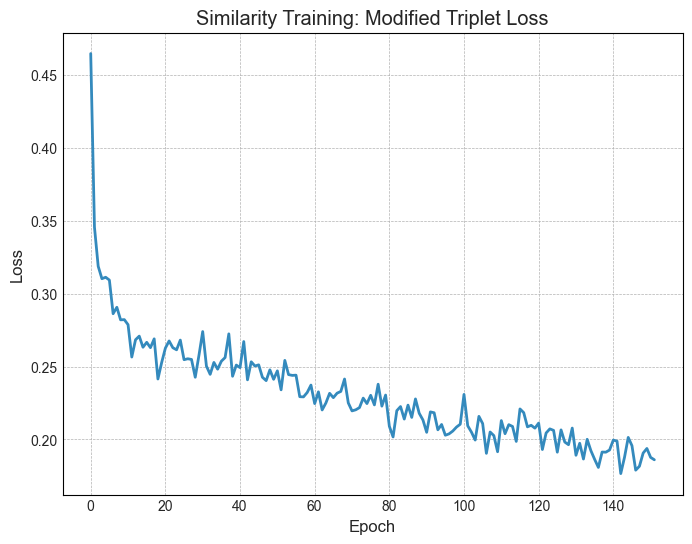

In [8]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use("bmh")
plt.rcParams.update({"figure.figsize" : (8, 6),
                     "axes.facecolor" : "white",
                     "axes.edgecolor":  "black"})
plt.plot(loss_history)
# plt.ylim(0, 1)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Similarity Training: Modified Triplet Loss")
plt.show()

# MISC Cells Below

In [24]:
from data.swarmset import ContinuingDataset, SwarmDataset
from src.networks.video_encoder import NoveltyVideoEmbedding
import numpy as np
import torch

device = "cpu"

NETWORK_PATH = "~/Desktop/DevProjects/SwarmBehaviorDiscovery/src/z-experiments/Sum24-notebooks/checkpoints/embeddings/videoF.pt"
network = NoveltyVideoEmbedding(out_size=32)
network.load_model(NETWORK_PATH, absolute=True)
network.eval().to(device)

embeddings = []
classes = []
# for i in range(len(data)):
sampled_dataset = SwarmDataset("data/single_video", rank=0, video=True)
for i in range(500):
    image = sampled_dataset[i][0]
    embed = network.numpy_single_pass(image)
    embed = embed.detach().cpu().squeeze(dim=0).numpy()
    embeddings.append(embed)

Initialized Network with  468928 parameters


In [25]:
def CSVLineToVec(line):
    line_list = line.strip().replace("\n", "").split(",")
    float_list = []
    for i in line_list:
        float_list.append(float(i))
    float_list = np.array(float_list)
    return float_list

def fetch_label_set(file):
    class_list = []
    with open(file, "r") as f:
        lines = f.readlines()
        class_list = [-1 for _ in range(len(lines))]
        for line in lines:
            triplet = CSVLineToVec(line)
            class_list[int(triplet[0])] = int(triplet[1])
    class_set = [(i, class_list[i]) for i in range(len(class_list))]
    return class_set, class_list

ls, classes = fetch_label_set("~/Desktop/DevProjects/SwarmBehaviorDiscovery/src/z-experiments/Sum24-notebooks/data/oracle_labels/single.csv")
MARGIN = 1

print("Total Testing Labels: ", len(ls))

# Evaluate Accuracy
correct, total = 0, 0
class_counts = {i:0 for i in range(max(classes) + 1)}
class_accuracy = {i:0 for i in range(max(classes) + 1)}
for l in range(len(ls)):
    x, _classX = ls[l]
    break_class_X = False
    if _classX == 0:
        continue
    for j in range(l, len(ls)):
        y, _classY = ls[j]
        # print(x, y, _classX, _classY)
        if x == y or _classX != _classY:
            continue
        for k in range(len(ls)):
            z, _classZ = ls[k]
            # print(z)
            # if _classZ == 0:
            #     continue
            # print(x, y, z)
            if _classZ == _classX or x == z or y == z:
                continue
            positive_dist = np.linalg.norm(embeddings[x] - embeddings[y])
            negative_dist = np.linalg.norm(embeddings[x] - embeddings[z])
            if positive_dist + MARGIN < negative_dist:
                correct += 1
                class_accuracy[_classX] += 1
            total += 1
            class_counts[_classX] += 1

print(class_counts)
print(f"CLASS ACCURACY (Out of {total} triplets):")
for class_value in class_accuracy:
    if class_value == 0 or class_counts[class_value] == 0:
        continue
    print(f"{class_value}: {class_accuracy[class_value] * 100 / class_counts[class_value]}")
acc = correct * 100 / total
print(f"Ensemble {i} ~ Accuracy: {acc}")

Total Testing Labels:  500
{0: 0, 1: 1357560, 2: 450450, 3: 1011126, 4: 730626, 5: 166023}
CLASS ACCURACY (Out of 3715785 triplets):
1: 82.41919325849318
2: 64.51370851370851
3: 71.87501854368298
4: 74.86703183297611
5: 87.94504375899724
Ensemble 499 ~ Accuracy: 76.14127297462043


In [26]:
from sklearn.manifold import TSNE
import numpy as np
reduced = TSNE(
    n_components=3,
    learning_rate="auto",
    init="pca",
    perplexity=50,
    early_exaggeration=8
).fit_transform(np.array(embeddings))

~/anaconda3/envs/BehaviorDiscovery/lib/python3.10/site-packages/sklearn/manifold/_t_sne.py:996: FutureWarning: The PCA initialization in TSNE will change to have the standard deviation of PC1 equal to 1e-4 in 1.2. This will ensure better convergence.
  warnings.warn(


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


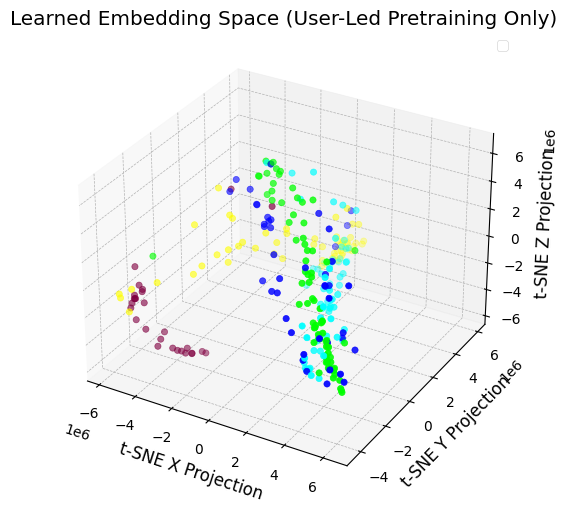

In [27]:
import matplotlib.pyplot as plt
import os

color_classes = {
    -1: [0.33, 0.33, 0.33],
    0: [1, 0, 0], # Red
    1: [0, 1, 0], # Green
    2: [0, 0, 1], # Blue
    3: [0, 1, 1], # Cyan
    4: [1, 1, 0], # Yellow
    5: [0.5, 0, 0.25], # Pink
    6: [0, 0, 0]
}

label_classes = {
    -1: "Unlabeled",
    0: "Random",
    1: "Cyclic Pursuit",
    2: "Milling",
    3: "Aggregation",
    4: "Dispersal",
    5: "Wall Following",
    6: "Special"
}

def CSVLineToVec(line):
    line_list = line.strip().replace("\n", "").split(",")
    float_list = []
    for i in line_list:
        float_list.append(float(i))
    float_list = np.array(float_list)
    return float_list

classes = [-1 for i in range(500)]
with open("~/Desktop/DevProjects/SwarmBehaviorDiscovery/src/z-experiments/Sum24-notebooks/data/oracle_labels/single.csv", "r") as f:
    lines = f.readlines()
    for line in lines:
        triplet = CSVLineToVec(line)
        classes[int(triplet[0])] = int(triplet[1])

lim = len(reduced)
RANDOM = 0
x = [reduced[i][0] for i in range(lim) if classes[i] != RANDOM]
y = [reduced[i][1] for i in range(lim) if classes[i] != RANDOM]
z = [reduced[i][2] for i in range(lim) if classes[i] != RANDOM]
colors = [color_classes[classes[i]] for i in range(lim) if classes[i] != RANDOM]
# labels = [label_classes[classes[i]] for i in range(lim)  if classes[i] != RANDOM]
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter(x, y, z, c=colors)
# ax.set_xlim(-200, 175)
# ax.set_ylim(-50, 400)
# ax.set_zlim(-2, 2)
ax.set_title("Learned Embedding Space (User-Led Pretraining Only)")
ax.set_xlabel("t-SNE X Projection")
ax.set_ylabel("t-SNE Y Projection")
ax.set_zlabel("t-SNE Z Projection")
ax.legend()

plt.show()